# Notebook 2 — Clasificación multiclase

Predecimos la situación final del estudiante (`abandono`, `matriculado`,
`graduado`) usando tres modelos de clasificación supervisada.

La lógica está en `src/clasificacion.py`. Desde aquí se realizan las llamadas a dicho modulo, se visualizan los resultados y se extraen conclusiones.

## Modelos

- **KNN**
- **Regresión Logística (ElasticNet)** — modelo lineal con regularización y `class_weight='balanced'`
- **Random Forest** — no lineal, robusto a multicolinealidad e interpretable gracias al feature importance

## Métrica principal: F1 macro

Las clases están desbalanceadas (graduado ~50 %, abandono ~32 %, matriculado
~18 %). El accuracy sería engañoso porque un clasificador que ignorara
`matriculado` aún así podría mantener buena precisión. El **F1 macro** penaliza ignorar las clases minoritarias. 

## 0. Configuración

In [13]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / 'src'))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import clasificacion
from configuracion import (
    CLASIFICACION_TRAIN, CLASIFICACION_TEST,
    CONFUSION_PREFIX, FEATURE_IMPORTANCE_CLF,
    RESUMEN_CLASIFICACION, PREDICCIONES_CLASIFICACION,
    RESULTS_DIR,
)

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
print(f'Train: {CLASIFICACION_TRAIN}')
print(f'Test:  {CLASIFICACION_TEST}')

Train: C:\Users\mb6ja\OneDrive\Documentos\ICAI\2\Machine_Learning\Proyecto_final_Machine_Learning\data\processed\datos_limpios_clasificacion_train.csv
Test:  C:\Users\mb6ja\OneDrive\Documentos\ICAI\2\Machine_Learning\Proyecto_final_Machine_Learning\data\processed\datos_limpios_clasificacion_test.csv


## 1. Carga de datos

Leemos los CSVs producidos por el notebook de preprocesado, aplicamos un
shuffle de seguridad al train y separamos features/target.

In [14]:
X_train, y_train, X_test, y_test = clasificacion.cargar_datos(str(CLASIFICACION_TRAIN), str(CLASIFICACION_TEST))

print(f'Train: {X_train.shape[0]} registros x {X_train.shape[1]} features')
print(f'Test:  {X_test.shape[0]} registros')
print(f'\nDistribución del target en train:')
print(y_train.value_counts().sort_index())
print(f'\nCodificación: 0=abandono, 1=matriculado, 2=graduado')

Train: 3539 registros x 35 features
Test:  885 registros

Distribución del target en train:
objetivo
0    1137
1     635
2    1767
Name: count, dtype: int64

Codificación: 0=abandono, 1=matriculado, 2=graduado


## 2. Preprocesador

Definimos un `ColumnTransformer` que contiene dos transformaciones:

- **`StandardScaler`** sobre las variables numéricas — imprescindible para KNN y la
  regresión logística regularizada.
- **`OneHotEncoder`** sobre las categóricas con `handle_unknown='ignore'`
  para no fallar si en test aparece alguna categoría no vista.

Ir dentro de un `Pipeline` asegura que estas transformaciones se
**ajustan sólo con el fold de entrenamiento** en cada iteración de la
validación cruzada, evitando leakage del fold de validación.

In [15]:
preprocesador = clasificacion.construir_preprocesador(X_train)
cols_num = X_train.select_dtypes(include=['int64', 'float64']).columns.tolist()
cols_cat = X_train.select_dtypes(include=['object', 'category']).columns.tolist()
print(f'Numéricas   ({len(cols_num)}): {cols_num}')
print(f'\nCategóricas ({len(cols_cat)}): {cols_cat}')

Numéricas   (19): ['orden_solicitud', 'nota_cualificacion_previa', 'nota_admision', 'edad_al_matricularse', 'asignaturas_1sem_convalidadas', 'asignaturas_1sem_matriculadas', 'asignaturas_1sem_evaluadas', 'asignaturas_1sem_aprobadas', 'nota_media_1sem', 'asignaturas_1sem_sin_evaluacion', 'asignaturas_2sem_convalidadas', 'asignaturas_2sem_matriculadas', 'asignaturas_2sem_evaluadas', 'asignaturas_2sem_aprobadas', 'nota_media_2sem', 'asignaturas_2sem_sin_evaluacion', 'tasa_desempleo', 'tasa_inflacion', 'pib']

Categóricas (16): ['estado_civil', 'modo_solicitud', 'curso', 'asistencia_diurna_vespertina', 'cualificacion_previa', 'cualificacion_madre', 'cualificacion_padre', 'ocupacion_madre', 'ocupacion_padre', 'desplazado', 'necesidades_educativas_especiales', 'deudor', 'matricula_al_dia', 'genero', 'becado', 'internacional']


## 2.5 Baseline (DummyClassifier)

Antes de entrenar ningún modelo real establecemos un baseline
con un `DummyClassifier`. Cualquier modelo que no supere este baseline será descartado puesto que no aporta ningún valor.

Comparamos dos estrategias:

| Estrategia | Descripción |
|---|---|
| `most_frequent` | Predice siempre la clase mayoritaria (`graduado`) |
| `stratified` | Respeta la distribución de las clases en train |

La referencia para nuestros modelos es el **F1 macro**, ya que es la métrica que usamos en GridSearchCV.

In [16]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import f1_score, classification_report

estrategias = ['most_frequent', 'stratified']
filas_baseline = []

for estrategia in estrategias:
    dummy = DummyClassifier(strategy=estrategia, random_state=0)
    dummy.fit(X_train, y_train)
    y_pred_dummy = dummy.predict(X_test)
    f1 = f1_score(y_test, y_pred_dummy, average='macro')
    filas_baseline.append({'modelo': f'Dummy ({estrategia})', 'f1_macro_test': f1})
    print(f"── Dummy strategy='{estrategia}' ──")
    print(classification_report(y_test, y_pred_dummy,
                                target_names=['abandono', 'matriculado', 'graduado'],
                                zero_division=0))

df_baseline = pd.DataFrame(filas_baseline)
print("Resumen baseline:")
print(df_baseline.to_string(index=False))

── Dummy strategy='most_frequent' ──
              precision    recall  f1-score   support

    abandono       0.00      0.00      0.00       284
 matriculado       0.00      0.00      0.00       159
    graduado       0.50      1.00      0.67       442

    accuracy                           0.50       885
   macro avg       0.17      0.33      0.22       885
weighted avg       0.25      0.50      0.33       885

── Dummy strategy='stratified' ──
              precision    recall  f1-score   support

    abandono       0.33      0.33      0.33       284
 matriculado       0.20      0.21      0.20       159
    graduado       0.50      0.49      0.50       442

    accuracy                           0.39       885
   macro avg       0.34      0.34      0.34       885
weighted avg       0.39      0.39      0.39       885

Resumen baseline:
               modelo  f1_macro_test
Dummy (most_frequent)       0.222055
   Dummy (stratified)       0.344102


## 3. Definición de modelos y grids

Para cada modelo definimos un espacio de hiperparámetros. La
búsqueda con GridSearchCV y 5 folds estratificados (para mantener la proporción de clases en cada fold) selecciona la
combinación que maximiza el F1 macro en validación.

In [17]:
modelos = clasificacion.definir_modelos_y_grids(preprocesador)
for nombre, (_, grid) in modelos.items():
    n_combos = int(np.prod([len(v) for v in grid.values()])) if grid else 1
    print(f'{nombre:22s}{n_combos:3d} combinaciones')

KNN                    28 combinaciones
LogisticRegression     12 combinaciones
RandomForest           36 combinaciones


## 4. Entrenamiento con validación cruzada

Ejecutamos GridSearchCV para cada modelo con `StratifiedKFold(5)`. Por cada combinación
de hiperparámetros se entrenan 5 modelos, por lo que esta celda puede
tardar.

In [18]:
resultados = clasificacion.entrenar_modelos(modelos, X_train, y_train, verbose=0)


------------------------------------------------------------
  Entrenando: KNN
------------------------------------------------------------
  Mejor F1 macro (CV): 0.6244
  Mejores params:      {'clf__metric': 'manhattan', 'clf__n_neighbors': 7, 'clf__weights': 'uniform'}

------------------------------------------------------------
  Entrenando: LogisticRegression
------------------------------------------------------------
  Mejor F1 macro (CV): 0.7113
  Mejores params:      {'clf__C': 0.1, 'clf__l1_ratio': 0.5}

------------------------------------------------------------
  Entrenando: RandomForest
------------------------------------------------------------
  Mejor F1 macro (CV): 0.7094
  Mejores params:      {'clf__max_depth': 20, 'clf__min_samples_leaf': 3, 'clf__n_estimators': 300}


## 5. Evaluación en test

Con los mejores hiperparámetros elegidos mediante CV, evaluamos cada modelo en el
conjunto de test.

In [19]:
labels = sorted(y_train.unique())  # [0, 1, 2]
nombres_clases = ['abandono', 'matriculado', 'graduado']

df_resumen, figs_cm = clasificacion.evaluar_en_test(
    resultados, X_test, y_test,
    labels=labels,
    nombres_clases=nombres_clases,
    guardar_figs=True,
    path_prefix_cm=str(CONFUSION_PREFIX),
    path_resumen_csv=str(RESUMEN_CLASIFICACION))


------------------------------------------------------------
  KNN  |  F1 macro test = 0.6531
------------------------------------------------------------
              precision    recall  f1-score   support

    abandono       0.83      0.68      0.75       284
 matriculado       0.52      0.33      0.41       159
    graduado       0.73      0.90      0.81       442

    accuracy                           0.73       885
   macro avg       0.69      0.64      0.65       885
weighted avg       0.72      0.73      0.72       885


------------------------------------------------------------
  LogisticRegression  |  F1 macro test = 0.7213
------------------------------------------------------------
              precision    recall  f1-score   support

    abandono       0.88      0.76      0.81       284
 matriculado       0.44      0.64      0.52       159
    graduado       0.86      0.80      0.83       442

    accuracy                           0.76       885
   macro avg       0

### 5.1 Tabla comparativa

In [20]:
# Tabla unificada: modelos reales + baseline
df_comparacion = pd.concat([
    df_resumen[['modelo', 'f1_macro_test']],
    df_baseline,
], ignore_index=True).sort_values('f1_macro_test', ascending=False)

df_comparacion['vs_mejor_baseline'] = (
    df_comparacion['f1_macro_test'] - df_baseline['f1_macro_test'].max()
).map(lambda x: f'+{x:.4f}' if x >= 0 else f'{x:.4f}')

df_comparacion.reset_index(drop=True)

,modelo,f1_macro_test,vs_mejor_baseline
0,RandomForest,0.724078,+0.3800
1,LogisticRegression,0.721286,+0.3772
2,KNN,0.653066,+0.3090
3,Dummy (stratified),0.344102,+0.0000
4,Dummy (most_frequent),0.222055,-0.1220


In [21]:
df_resumen.sort_values('f1_macro_test', ascending=False)

,modelo,f1_macro_cv,f1_macro_test,mejores_params
2,RandomForest,0.709409,0.724078,"{'clf__max_depth': 20, 'clf__min_samples_leaf'..."
1,LogisticRegression,0.711280,0.721286,"{'clf__C': 0.1, 'clf__l1_ratio': 0.5}"
0,KNN,0.624361,0.653066,"{'clf__metric': 'manhattan', 'clf__n_neighbors..."


### 5.2 Matrices de confusión

Las matrices de confusión nos dejan ver qué clases confunde cada modelo.
Es esperable que la clase `matriculado` sea la más difícil: está en medio
(no ha abandonado, pero tampoco se ha graduado).

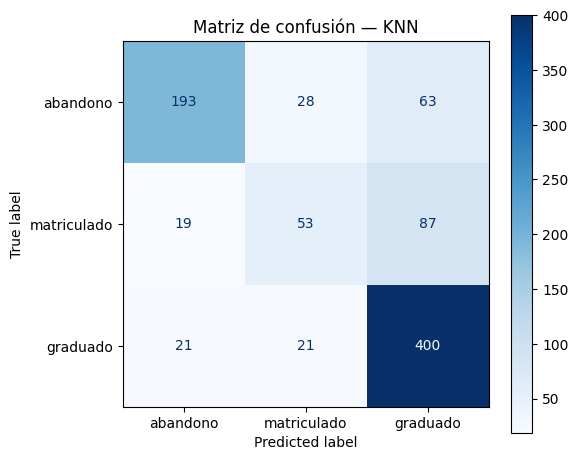

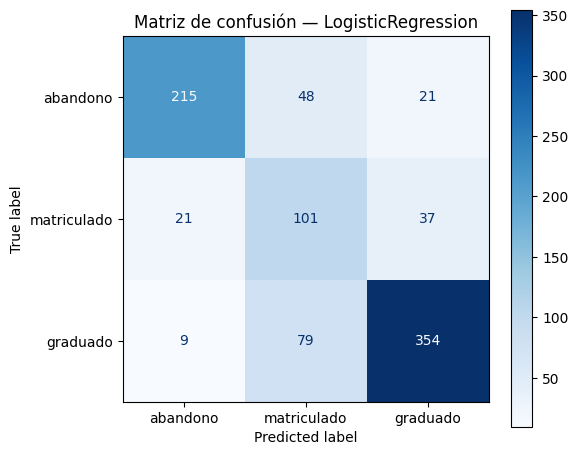

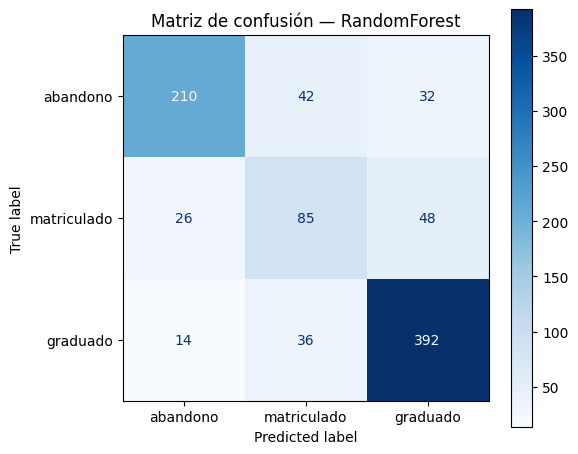

In [22]:
for nombre, fig in figs_cm.items():
    display(fig)

**Lectura de las matrices.**

- **Confusiones `matriculado` <-> `graduado`**: muy frecuentes porque ambos
  completaron el 1er semestre con rendimiento similar; lo único que los
  distingue es si en algún momento posterior completaron o no la titulación.
- **`abandono` bien separado**: sus variables académicas (nota 0, pocas
  asignaturas aprobadas) son muy distintivas, así que todos los modelos lo
  detectan con alta precisión.
- **Casos donde el modelo predice `abandono` pero es `graduado`**: son
  falsos positivos (positivo en abandonar) preocupantes desde el punto de vista institucional,
  porque llevarían a intervenciones innecesarias.
- **Casos donde el modelo predice `graduado` pero es `abandono`**: son
  falsos negativos preocupantes porque llevarían a ignorar ciertos perfiles 
  que necesitan intervención.

## 6. Importancia de variables (Random Forest)

El RF nos permite jerarquizar las variables por su contribución a la
reducción de impureza Gini a lo largo de todos los árboles.

,variable,importancia
0,asignaturas_2sem_aprobadas,0.122230
1,nota_media_2sem,0.097501
2,asignaturas_1sem_aprobadas,0.080008
3,nota_media_1sem,0.065971
4,asignaturas_2sem_evaluadas,0.049607
5,asignaturas_1sem_evaluadas,0.038479
6,edad_al_matricularse,0.036220
7,nota_admision,0.034397
8,matricula_al_dia_no,0.033179
9,nota_cualificacion_previa,0.029361


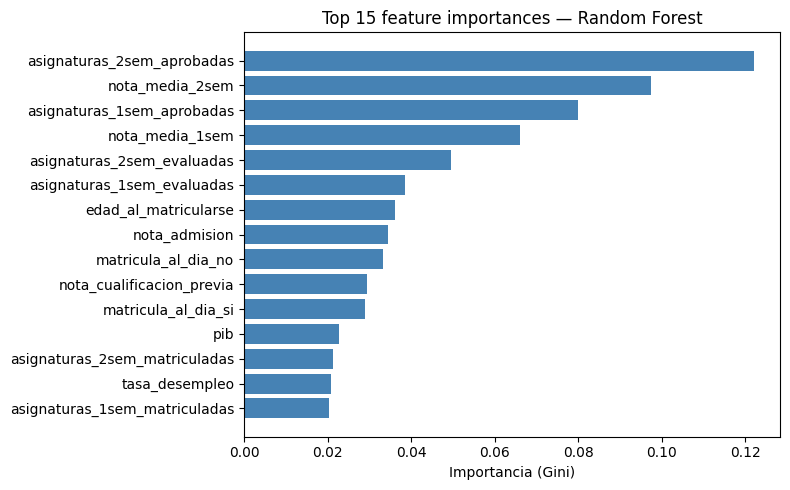

In [23]:
df_imp, fig_imp = clasificacion.importancia_variables(
    resultados['RandomForest'],
    top_n=15,
    path_fig=str(FEATURE_IMPORTANCE_CLF))

df_imp

**Interpretación.** Las variables de rendimiento del 2º semestre
(`nota_media_2sem`, `asignaturas_2sem_aprobadas`, `asignaturas_2sem_evaluadas`)
dominan la importancia, como era de esperar: el rendimiento del segundo semestre
es el predictor más fuerte de la trayectoria. Entre las no académicas destacan
`nota_admision`, `edad_al_matricularse` y como variable administrativa, `matricula_al_dia`,
asociadas al riesgo de abandono.

**Limitación:** la importancia de Gini está sesgada en presencia de
multicolinealidad. Para una lectura más robusta se podría complementar con
permutation importance.

## 7. Guardar predicciones del mejor modelo

Elegimos el modelo con mayor F1 macro en test y guardamos sus predicciones
sobre test en un CSV para entregar.

In [24]:
nombre_mejor = df_resumen.loc[df_resumen['f1_macro_test'].idxmax(), 'modelo']
gs_mejor = resultados[nombre_mejor]
f1_mejor = df_resumen['f1_macro_test'].max()
print(f'Mejor modelo: {nombre_mejor}  (F1 macro test = {f1_mejor:.4f})')

preds = pd.DataFrame({
    'y_real': y_test.values,
    'y_pred': gs_mejor.predict(X_test),
})
preds.to_csv(PREDICCIONES_CLASIFICACION, index=False)
print(f'Guardado: {PREDICCIONES_CLASIFICACION}')
preds.head()

Mejor modelo: RandomForest  (F1 macro test = 0.7241)
Guardado: C:\Users\mb6ja\OneDrive\Documentos\ICAI\2\Machine_Learning\Proyecto_final_Machine_Learning\results\predicciones_clasificacion.csv


,y_real,y_pred
0,0,2
1,2,2
2,0,0
3,0,2
4,0,1


## 8. Conclusiones

- El **Random Forest** suele ser el modelo con mejor F1 macro en test,
  aprovechando las interacciones no lineales entre variables académicas y
  administrativas.
- La **regresión logística** queda muy cerca con mucha menos complejidad,
  ofreciendo gran interpretabilidad gracias a los pesos.
- **KNN** tiende a ser el más débil por la dimensionalidad después de aplicar el one-hot:
  con muchas variables categóricas, la noción de distancia se vuelve confusa
  (curse of dimensionality).
- La clase **`matriculado`** es la más difícil de todas por su posición
  intermedia entre abandono y graduación y por el menor número de instancias en el dataset.
- El rendimiento académico del **2º semestre** es el predictor dominante.
  Esto sugiere que las intervenciones institucionales a lo largo del segundo semestre
  son el punto con mayor potencial de impacto.